# Hafta 3: Model Kıyaslaması (AVM Rehber Kiosk)

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leylagns/avm-kiosk-assistant/blob/main/notebooks/02_colab_week3.ipynb)

Bu not defteri **dört yöntemi aynı veri, aynı bölünme ve aynı ölçütlerle** karşılaştırır:

| Kod | Yöntem | Ne öğrenir? |
|---|---|---|
| **E0** | Kural tabanlı (sözlük + anahtar kelime) | Hiçbir şey öğrenmez, alt sınır |
| **E1** | TF-IDF (karakter n-gram) + Lojistik Regresyon | Klasik makine öğrenmesi baseline'ı |
| **E2a** | DistilBERTurk (küçük Transformer) | Türkçe önceden eğitilmiş hazır model, ince ayar |
| **E2b** | BERTurk (büyük Transformer) | Aynısı, daha büyük |

**Test setleri**
- `test`: eğitimle aynı şablon ailesi (kolay, sadece sanity check)
- `test_hard`: eğitimde olmayan şablonlar, örtük ifadeler, ağır gürültü
- `test_llm`: şablondan bağımsız, gerçek ziyaretçi tarzında cümleler. **Bir dil modeli yazdı, gerçek kullanıcı verisi değildir.** Gerçek sorgular toplanınca buraya eklenecek.

**Önce:** *Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU*. Sonra hücreleri sırayla çalıştır (toplam yaklaşık 15-30 dk).

> E3 (küçük LLM + LoRA) takvime göre Hafta 5'te eklenecek.

## 0. Ayarlar ve kurulum

In [ ]:
# Her çalıştırmada GitHub'daki EN GÜNCEL kodu al (eski kod kalmasın)
import os, sys, shutil
REPO = "https://github.com/leylagns/avm-kiosk-assistant.git"
if os.path.exists("/content"): os.chdir("/content")
if os.path.exists("avm-kiosk-assistant"): shutil.rmtree("avm-kiosk-assistant")
!git clone -q {REPO}
%cd avm-kiosk-assistant
for m in [m for m in sys.modules if m.startswith("kiosk_nlu")]: del sys.modules[m]   # eski modülleri bellekten at
!git log --oneline | head -3
!grep -n "entity_epochs" src/kiosk_nlu/bert_nlu.py | head -2

/content/avm-kiosk-assistant
b1372c5 Colab not defteri: her çalıştırmada güncel kodu yeniden klonla
0cb7737 Figma görsellerini kaldır, yalnızca bağlantı ve akış açıklaması kalsın
1dcc8f6 Figma bağlantısını README ve Hafta 2 belgelerine ekle
35:                 entity_epochs: int = 15, entity_lr: float = 5e-5):
39:        self.entity_epochs, self.entity_lr = entity_epochs, entity_lr


In [ ]:
!pip -q install transformers accelerate tabulate
%matplotlib inline
import sys, json, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, "src")
pd.set_option("display.width", 160, "display.max_colwidth", 70, "display.max_rows", 200)
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "yok (E2 yavaş olur)")

# --- AYARLAR ---
EPOCHS = 4            # BERT ince ayar epoch sayısı
RUN_BERT = True       # False yaparsan yalnızca E0 ve E1 çalışır (hızlı deneme)
N_BOOT = 1000         # bootstrap tekrar sayısı (güven aralığı için)
SEED = 42

GPU: True Tesla T4


## 1. Veri

Veri `generate_dataset.py` ile **şablon + rastgele katalog değerleri + gürültü** (yazım hatası, ASCII yazım, dolgu sözcüğü) kullanılarak üretilir. `seed=42` sabit olduğu için herkes aynı veriyi elde eder.
`test_llm` hazır dosyadır (repoda). Hiçbir test seti eğitimde kullanılmaz.

In [ ]:
!PYTHONPATH=src python -m kiosk_nlu.generate_dataset
from kiosk_nlu.generate_dataset import INTENTS
NAMES = ["train", "val", "test", "test_hard", "test_llm"]
D = {n: pd.read_csv(f"data/processed/{n}.csv") for n in NAMES}

# sızıntı kontrolü: kümeler arasında aynı metin var mı?
sets = {n: set(d.text) for n, d in D.items()}
leak = {(a, b): len(sets[a] & sets[b]) for i, a in enumerate(NAMES) for b in NAMES[i + 1:] if sets[a] & sets[b]}
print("Kümeler arası ortak metin:", leak if leak else "YOK (temiz)")
pd.DataFrame({n: {"satır": len(d), "benzersiz metin": d.text.nunique(), "ort. kelime": round(d.text.str.split().str.len().mean(), 2)} for n, d in D.items()}).T

train: 1540 satır
val: 245 satır
test: 280 satır
test_hard: 280 satır
Kümeler arası ortak metin: YOK (temiz)


,satır,benzersiz metin,ort. kelime
train,1540.0,1540.0,3.99
val,245.0,245.0,3.97
test,280.0,280.0,4.17
test_hard,280.0,280.0,5.04
test_llm,97.0,97.0,4.34


,train,val,test,test_hard,test_llm
intent,,,,,
find_store,220,35,40,40,20
find_facility,220,35,40,40,16
recommend_category,220,35,40,40,24
opening_hours,220,35,40,40,11
floor_directory,220,35,40,40,7
greeting_help,220,35,40,40,6
out_of_scope,220,35,40,40,13


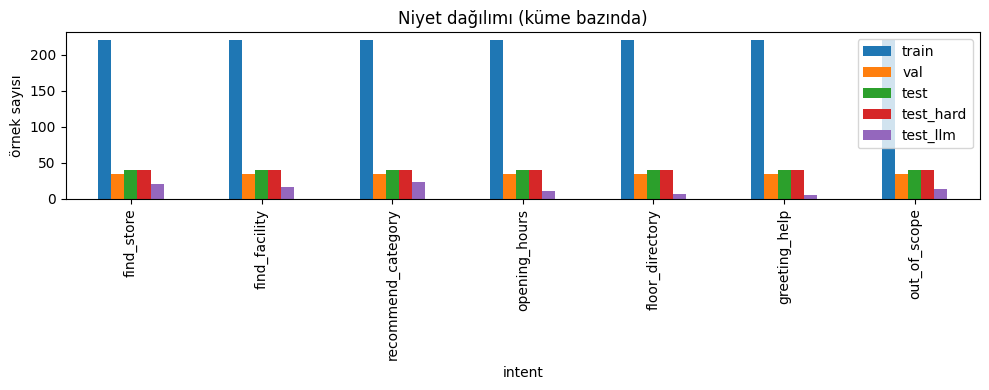

test_llm'den örnekler:


,text,intent,entity_value
33,bilgi noktası var mı,find_facility,danışma
58,market alışverişi yapacağım,recommend_category,market
32,danışma nerede kaybolduk,find_facility,danışma
90,bana bir fıkra anlat,out_of_scope,NaN
45,yeni telefon almayı düşünüyorum,recommend_category,elektronik
55,ilaç almam gerekiyor eczane var mı,recommend_category,eczane
66,alışveriş merkezi akşam kaça kadar açık,opening_hours,NaN
86,wifi şifresi nedir,out_of_scope,NaN
89,bu akşam maç var mı,out_of_scope,NaN
59,elbise bakmak istiyorum,recommend_category,giyim


In [ ]:
dist = pd.DataFrame({n: d.intent.value_counts() for n, d in D.items()}).reindex(INTENTS).fillna(0).astype(int)
display(dist)
ax = dist.plot(kind="bar", figsize=(10, 4), title="Niyet dağılımı (küme bazında)")
ax.set_ylabel("örnek sayısı"); plt.tight_layout(); plt.show()
print("test_llm'den örnekler:")
display(D["test_llm"].sample(10, random_state=1)[["text", "intent", "entity_value"]])

**Ne oldu?** Beş küme hazır. `test_llm`'deki cümleler şablonlara hiç benzemiyor; modelin gerçekten genelleyip genelleyemediğini bu küme gösterir.

## 2. Modelleri kur ve eğit

- **E0** eğitim istemez.
- **E1**: `C` ayarı **yalnızca `val` kümesiyle** seçilir.
- **E2a / E2b**: iki baş eğitilir (niyet ve varlık). Her epoch'ta `loss` düşmelidir.

In [ ]:
from sklearn.metrics import f1_score
from kiosk_nlu.rules import RuleNLU
from kiosk_nlu.baseline import BaselineNLU

train, val = D["train"], D["val"]
MODELS, TRAIN_SEC, PARAMS = {}, {}, {}

MODELS["E0 Kural"] = RuleNLU(); TRAIN_SEC["E0 Kural"] = 0.0; PARAMS["E0 Kural"] = 0

t0 = time.time(); best_c, best_f1 = None, -1
for c in [1, 10, 100]:
    m = BaselineNLU(C=c).fit(train.text, train.intent)
    f1 = f1_score(val.intent, m.predict_intents(val.text), average="macro")
    print(f"E1  C={c:<4} val makro-F1={f1:.3f}")
    if f1 > best_f1: best_c, best_f1 = c, f1
e1 = BaselineNLU(C=best_c).fit(train.text, train.intent)
MODELS["E1 TF-IDF+LR"] = e1; TRAIN_SEC["E1 TF-IDF+LR"] = time.time() - t0
PARAMS["E1 TF-IDF+LR"] = len(e1.clf[0].vocabulary_) * len(INTENTS)   # öznitelik x sınıf ağırlığı
print("E1 seçilen C:", best_c)

E1  C=1    val makro-F1=1.000
E1  C=10   val makro-F1=1.000
E1  C=100  val makro-F1=1.000
E1 seçilen C: 1


In [ ]:
if RUN_BERT:
    from kiosk_nlu.bert_nlu import BertNLU
    for name, hf in [("E2a DistilBERTurk", "dbmdz/distilbert-base-turkish-cased"),
                     ("E2b BERTurk", "dbmdz/bert-base-turkish-cased")]:
        print("=" * 60, "\n", name, hf)
        t0 = time.time()
        m = BertNLU(model_name=hf, epochs=EPOCHS, seed=SEED).fit(train)
        TRAIN_SEC[name] = time.time() - t0; PARAMS[name] = m.n_params(); MODELS[name] = m
        print(f"{name}: eğitim {TRAIN_SEC[name]:.0f} sn, {PARAMS[name] / 1e6:.0f} M parametre")
print("Hazır modeller:", list(MODELS))

 E2a DistilBERTurk dbmdz/distilbert-base-turkish-cased


config.json:   0%|          | 0.00/410 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/251k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  273MB            

model.safetensors: downloading bytes:           |  0.00B            

... (13 outputs left out)

[niyet] epoch 1/4  loss=1.6280
[niyet] epoch 2/4  loss=0.3044
[niyet] epoch 3/4  loss=0.0376
[niyet] epoch 4/4  loss=0.0145


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[varlık] epoch 1/15  loss=4.1312
[varlık] epoch 2/15  loss=3.3228
[varlık] epoch 3/15  loss=1.7940
[varlık] epoch 4/15  loss=0.8224
[varlık] epoch 5/15  loss=0.3956
[varlık] epoch 6/15  loss=0.1961
[varlık] epoch 7/15  loss=0.1087
[varlık] epoch 8/15  loss=0.0697
[varlık] epoch 9/15  loss=0.0532
[varlık] epoch 10/15  loss=0.0430
[varlık] epoch 11/15  loss=0.0378
[varlık] epoch 12/15  loss=0.0332
[varlık] epoch 13/15  loss=0.0306
[varlık] epoch 14/15  loss=0.0289
[varlık] epoch 15/15  loss=0.0281
E2b BERTurk: eğitim 207 sn, 221 M parametre
Hazır modeller: ['E0 Kural', 'E1 TF-IDF+LR', 'E2a DistilBERTurk', 'E2b BERTurk']


**Ne oldu?** Modeller eğitildi. `loss` her epoch'ta düştüyse eğitim sağlıklı. Eğitim süresi ve parametre sayısı, sonraki 'boyut–hız–başarı' grafiğinde kullanılacak.

## 3. Değerlendirme

Her model her kümede ölçülür. Metrikler:
- **Niyet doğruluğu / makro-F1** (Q1 hedefi: zor testte makro-F1 ≥ 0,85)
- **Varlık doğruluğu** (Q2 hedefi: zor testte ≥ 0,85)
- **Uçtan uca doğruluk:** niyet ve varlık birlikte doğru
- **Gecikme** (p95, Q3 hedefi ≤ 500 ms; burada yalnızca NLU kısmı)
- **%95 güven aralığı:** test kümesi örneklerinden 1000 kez yeniden örnekleyerek (bootstrap)

In [ ]:
from kiosk_nlu.evaluate import evaluate_split, TARGETS

SETS = ["val", "test", "test_hard", "test_llm"]
OUT, MET = {}, {}
for mn, m in MODELS.items():
    for _ in range(5): m.parse("merhaba")            # ısınma (GPU/önbellek)
    for s in SETS:
        OUT[(mn, s)], MET[(mn, s)] = evaluate_split(m, D[s])
print("Değerlendirme tamam.")

def boot_ci(out, n=N_BOOT, seed=0):
    rng = np.random.default_rng(seed)
    y, p = out.intent.values, out.pred_intent.values
    accs, f1s = [], []
    for _ in range(n):
        i = rng.integers(0, len(out), len(out))
        accs.append((y[i] == p[i]).mean())
        f1s.append(f1_score(y[i], p[i], average="macro", labels=INTENTS, zero_division=0))
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(accs, [2.5, 97.5])

CI = {(mn, s): boot_ci(OUT[(mn, s)]) for mn in MODELS for s in ["test", "test_hard", "test_llm"]}
print("Güven aralıkları hesaplandı.")

Değerlendirme tamam.
Güven aralıkları hesaplandı.


## 4. Ana sonuç tablosu

In [ ]:
rows = []
for mn in MODELS:
    for s in ["test", "test_hard", "test_llm"]:
        m, (f1ci, _) = MET[(mn, s)], CI[(mn, s)]
        rows.append({"Model": mn, "Küme": s, "n": m["n"], "Niyet doğr.": m["intent_acc"],
                     "Makro-F1": m["intent_macro_f1"], "F1 %95 GA": f"[{f1ci[0]:.2f}, {f1ci[1]:.2f}]",
                     "Varlık doğr.": m["entity_acc"], "Uçtan uca": m["end_to_end_acc"], "p95 ms": m["latency_p95_ms"]})
SUMMARY = pd.DataFrame(rows)
display(SUMMARY.round(3))
display(SUMMARY.pivot(index="Model", columns="Küme", values="Makro-F1").round(3)[["test", "test_hard", "test_llm"]]
        .style.background_gradient(cmap="Greens", vmin=0.5, vmax=1.0))

,Model,Küme,n,Niyet doğr.,Makro-F1,F1 %95 GA,Varlık doğr.,Uçtan uca,p95 ms
0,E0 Kural,test,280,0.882,0.880,"[0.84, 0.92]",0.948,0.882,20.389
1,E0 Kural,test_hard,280,0.675,0.688,"[0.65, 0.73]",0.793,0.675,28.314
2,E0 Kural,test_llm,97,0.887,0.866,"[0.75, 0.93]",0.908,0.876,37.807
3,E1 TF-IDF+LR,test,280,1.000,1.000,"[1.00, 1.00]",0.974,0.982,11.636
4,E1 TF-IDF+LR,test_hard,280,0.664,0.673,"[0.62, 0.72]",0.601,0.621,14.218
5,E1 TF-IDF+LR,test_llm,97,0.680,0.717,"[0.60, 0.79]",0.671,0.639,11.287
6,E2a DistilBERTurk,test,280,0.943,0.943,"[0.92, 0.97]",0.907,0.929,11.416
7,E2a DistilBERTurk,test_hard,280,0.671,0.670,"[0.62, 0.71]",0.660,0.643,17.501
8,E2a DistilBERTurk,test_llm,97,0.732,0.770,"[0.67, 0.85]",0.711,0.680,15.399
9,E2b BERTurk,test,280,0.989,0.989,"[0.98, 1.00]",0.995,0.989,22.745


Küme,test,test_hard,test_llm
Model,,,
E0 Kural,0.880000,0.688000,0.866000
E1 TF-IDF+LR,1.000000,0.673000,0.717000
E2a DistilBERTurk,0.943000,0.670000,0.770000
E2b BERTurk,0.989000,0.816000,0.882000


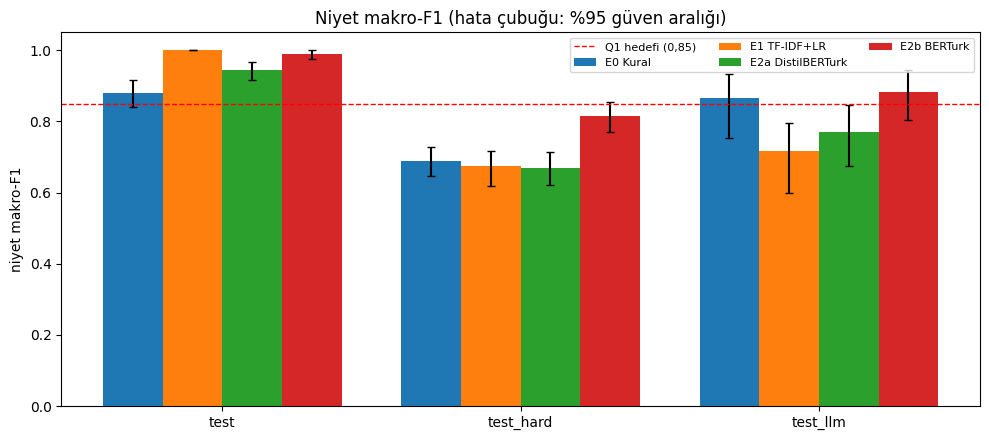

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
w, ks = 0.8 / len(MODELS), ["test", "test_hard", "test_llm"]
for j, mn in enumerate(MODELS):
    v = [MET[(mn, s)]["intent_macro_f1"] for s in ks]
    err = [[v[i] - CI[(mn, s)][0][0] for i, s in enumerate(ks)], [CI[(mn, s)][0][1] - v[i] for i, s in enumerate(ks)]]
    ax.bar(np.arange(3) + j * w, v, w, yerr=err, capsize=3, label=mn)
ax.axhline(TARGETS["intent_macro_f1_hard"], color="red", ls="--", lw=1, label="Q1 hedefi (0,85)")
ax.set_xticks(np.arange(3) + w * (len(MODELS) - 1) / 2, ks); ax.set_ylim(0, 1.05)
ax.set_ylabel("niyet makro-F1"); ax.set_title("Niyet makro-F1 (hata çubuğu: %95 güven aralığı)"); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); os.makedirs("docs/week3/figures", exist_ok=True)
plt.savefig("docs/week3/figures/cmp_macro_f1.png", dpi=130); plt.show()

**Nasıl okunur?** Çubukların tepesindeki çizgi güven aralığı. İki modelin aralıkları üst üste biniyorsa aradaki farka **güvenme**, tesadüf olabilir. Kırmızı çizgi öneri formundaki hedef.

## 5. Hedeflerle kıyaslama (öneri formu)

In [ ]:
def durum(v, t, alt=False): return "✅" if (v <= t if alt else v >= t) else "❌"
trows = []
for s in ["test_hard", "test_llm"]:
    for mn in MODELS:
        m = MET[(mn, s)]
        trows.append({"Küme": s, "Model": mn,
                      "Q1 makro-F1 (≥0,85)": f"{m['intent_macro_f1']:.3f} {durum(m['intent_macro_f1'], TARGETS['intent_macro_f1_hard'])}",
                      "Q2 varlık (≥0,85)": f"{m['entity_acc']:.3f} {durum(m['entity_acc'], TARGETS['entity_acc_hard'])}",
                      "Q3 p95 ms (≤500)": f"{m['latency_p95_ms']:.1f} {durum(m['latency_p95_ms'], TARGETS['p95_latency_ms'], True)}"})
TARGET_TABLE = pd.DataFrame(trows)
display(TARGET_TABLE)

,Küme,Model,"Q1 makro-F1 (≥0,85)","Q2 varlık (≥0,85)",Q3 p95 ms (≤500)
0,test_hard,E0 Kural,0.688 ❌,0.793 ❌,28.3 ✅
1,test_hard,E1 TF-IDF+LR,0.673 ❌,0.601 ❌,14.2 ✅
2,test_hard,E2a DistilBERTurk,0.670 ❌,0.660 ❌,17.5 ✅
3,test_hard,E2b BERTurk,0.816 ❌,0.809 ❌,30.3 ✅
4,test_llm,E0 Kural,0.866 ✅,0.908 ✅,37.8 ✅
5,test_llm,E1 TF-IDF+LR,0.717 ❌,0.671 ❌,11.3 ✅
6,test_llm,E2a DistilBERTurk,0.770 ❌,0.711 ❌,15.4 ✅
7,test_llm,E2b BERTurk,0.882 ✅,0.934 ✅,21.1 ✅


## 6. Karışıklık matrisleri

Satır = gerçek niyet, sütun = modelin tahmini. Köşegen doğru, köşegen dışı hata. **Hangi niyet hangisine karışıyor?** burada görülür.

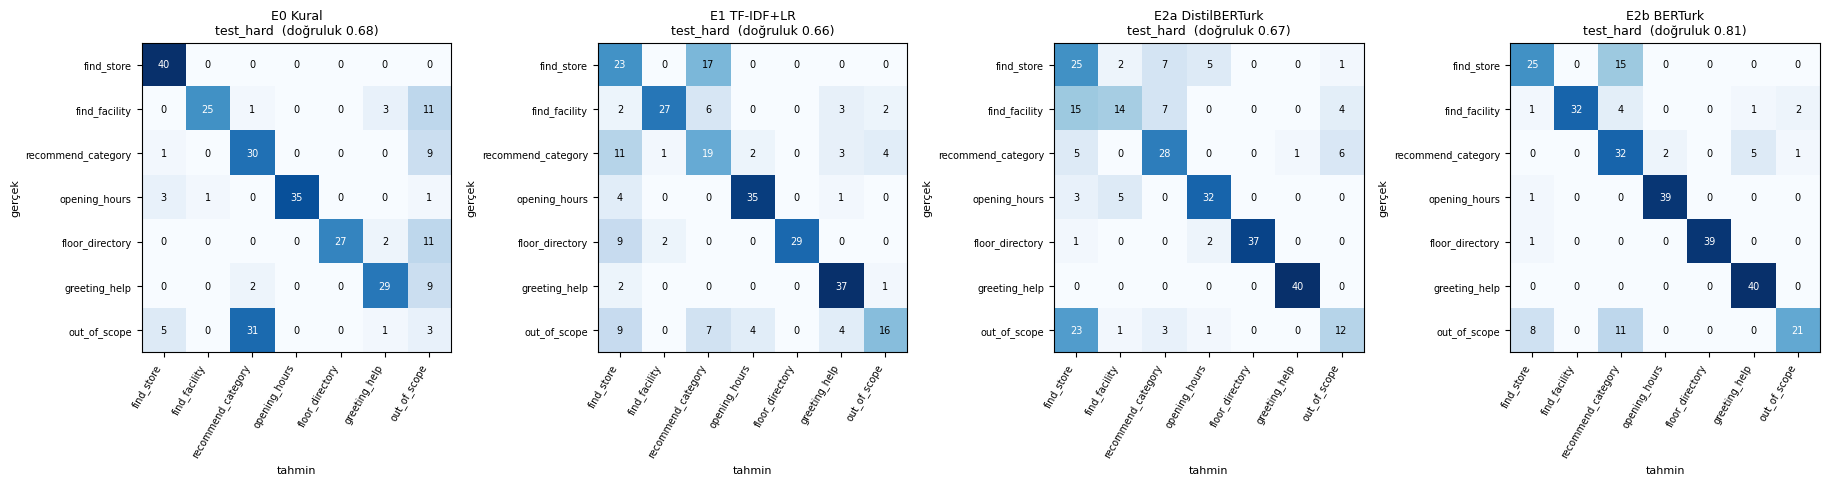

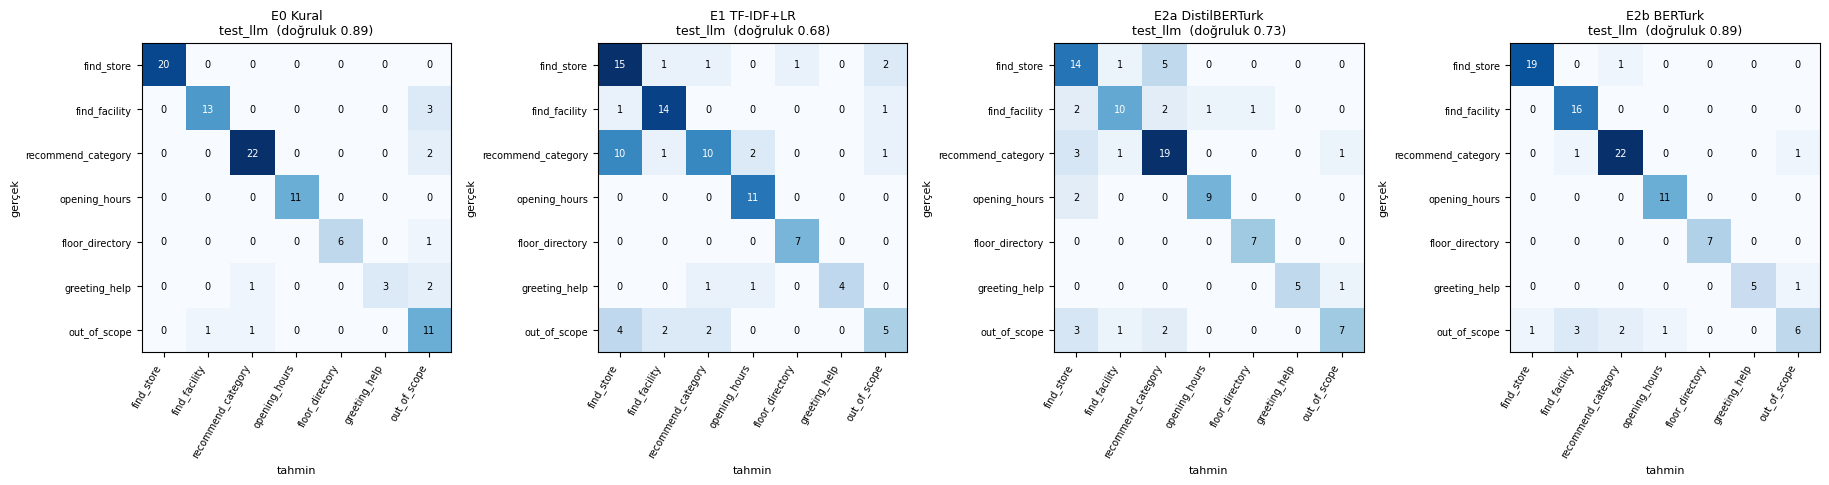

In [ ]:
from sklearn.metrics import confusion_matrix
def plot_cms(s):
    n = len(MODELS)
    fig, axes = plt.subplots(1, n, figsize=(4.6 * n, 4.8))
    axes = np.atleast_1d(axes)
    for ax, mn in zip(axes, MODELS):
        o = OUT[(mn, s)]
        cm = confusion_matrix(o.intent, o.pred_intent, labels=INTENTS)
        ax.imshow(cm, cmap="Blues")
        ax.set_xticks(range(len(INTENTS)), INTENTS, rotation=60, ha="right", fontsize=7)
        ax.set_yticks(range(len(INTENTS)), INTENTS, fontsize=7)
        for i in range(len(INTENTS)):
            for j in range(len(INTENTS)):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_title(f"{mn}\n{s}  (doğruluk {MET[(mn, s)]['intent_acc']:.2f})", fontsize=9)
        ax.set_xlabel("tahmin", fontsize=8); ax.set_ylabel("gerçek", fontsize=8)
    plt.tight_layout(); plt.savefig(f"docs/week3/figures/cmp_confusion_{s}.png", dpi=120); plt.show()
plot_cms("test_hard"); plot_cms("test_llm")

## 7. Niyet bazında F1 (hangi niyet zayıf?)

In [ ]:
from sklearn.metrics import classification_report
def per_intent(s):
    d = {}
    for mn in MODELS:
        o = OUT[(mn, s)]
        r = classification_report(o.intent, o.pred_intent, labels=INTENTS, output_dict=True, zero_division=0)
        d[mn] = {k: r[k]["f1-score"] for k in INTENTS}
    return pd.DataFrame(d)
for s in ["test_hard", "test_llm"]:
    print(f"--- {s}: niyet bazında F1 ---")
    display(per_intent(s).round(2).style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

--- test_hard: niyet bazında F1 ---


,E0 Kural,E1 TF-IDF+LR,E2a DistilBERTurk,E2b BERTurk
find_store,0.900000,0.460000,0.450000,0.660000
find_facility,0.760000,0.770000,0.450000,0.890000
recommend_category,0.580000,0.430000,0.660000,0.630000
opening_hours,0.930000,0.860000,0.800000,0.960000
floor_directory,0.810000,0.840000,0.960000,0.990000
greeting_help,0.770000,0.840000,0.990000,0.930000
out_of_scope,0.070000,0.510000,0.380000,0.660000


--- test_llm: niyet bazında F1 ---


,E0 Kural,E1 TF-IDF+LR,E2a DistilBERTurk,E2b BERTurk
find_store,1.000000,0.600000,0.640000,0.950000
find_facility,0.870000,0.820000,0.690000,0.890000
recommend_category,0.920000,0.530000,0.730000,0.900000
opening_hours,1.000000,0.880000,0.860000,0.960000
floor_directory,0.920000,0.930000,0.930000,1.000000
greeting_help,0.670000,0.800000,0.910000,0.910000
out_of_scope,0.690000,0.450000,0.640000,0.570000


## 8. Varlık çıkarımı (türe göre doğruluk)

In [ ]:
def per_entity(s):
    d = {}
    for mn in MODELS:
        o = OUT[(mn, s)]; o = o[o.entity_type.notna()]
        d[mn] = o.groupby("entity_type").entity_ok.mean()
    return pd.DataFrame(d)
for s in ["test_hard", "test_llm"]:
    print(f"--- {s}: varlık doğruluğu (tür bazında) ---")
    display(per_entity(s).round(2).style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

--- test_hard: varlık doğruluğu (tür bazında) ---


,E0 Kural,E1 TF-IDF+LR,E2a DistilBERTurk,E2b BERTurk
entity_type,,,,
category,0.750000,0.420000,0.600000,0.780000
facility,0.620000,0.450000,0.350000,0.800000
floor,0.680000,0.700000,0.900000,0.980000
store,0.990000,0.740000,0.740000,0.740000


--- test_llm: varlık doğruluğu (tür bazında) ---


,E0 Kural,E1 TF-IDF+LR,E2a DistilBERTurk,E2b BERTurk
entity_type,,,,
category,0.880000,0.330000,0.670000,0.880000
facility,0.810000,0.810000,0.620000,0.940000
floor,0.860000,0.860000,1.000000,1.000000
store,1.000000,0.830000,0.720000,0.970000


**Soru (kendine sor):** Kategori varlığı ('acıktım' → yemek) neden sözlük yöntemlerinde (E0, E1) zayıf? Cevap: sözlük yalnızca yazılı kelimeyi bulabilir, cümlenin anlamını çıkaramaz.

## 9. Hata analizi

In [ ]:
def ok_of(o): return (o.intent_ok & (o.entity_ok | o.entity_type.isna())).values
def error_table(s):
    base = D[s][["text", "intent", "entity_value"]].copy()
    for mn in MODELS:
        o = OUT[(mn, s)]
        base[f"{mn.split()[0]} niyet"] = o.pred_intent.values
        base[f"{mn.split()[0]} varlık"] = o.pred_entity.values
        base[f"{mn.split()[0]} ok"] = ok_of(o)
    return base
E = error_table("test_llm")
okcols = [c for c in E.columns if c.endswith(" ok")]
E["kaç model doğru"] = E[okcols].sum(axis=1)
print(f"test_llm: tüm modellerin yanlış yaptığı örnek sayısı: {(E['kaç model doğru'] == 0).sum()} / {len(E)}")
display(E[E["kaç model doğru"] == 0][["text", "intent", "entity_value"] + [c for c in E.columns if c.endswith(("niyet", "varlık"))]].head(25))

test_llm: tüm modellerin yanlış yaptığı örnek sayısı: 4 / 97


,text,intent,entity_value,E0 niyet,E0 varlık,E1 niyet,E1 varlık,E2a niyet,E2a varlık,E2b niyet,E2b varlık
34,çocuğumu kaybettim güvenliğe nereden ulaşırım,find_facility,danışma,out_of_scope,None,find_store,None,recommend_category,mücevher,find_facility,bebek bakım odası
36,karnım acıktı bi şeyler yiyelim,recommend_category,yemek,out_of_scope,None,opening_hours,None,find_store,S21,out_of_scope,None
85,taksi çağırır mısın,out_of_scope,NaN,recommend_category,mücevher,recommend_category,mücevher,recommend_category,elektronik,recommend_category,yemek
87,otopark ücreti ne kadar,out_of_scope,NaN,find_facility,otopark,find_facility,otopark,find_facility,otopark,find_facility,otopark


In [ ]:
if len(MODELS) >= 4:
    best, weak = "E2b", "E1"
    d = E[(E[f"{best} ok"]) & (~E[f"{weak} ok"])]
    print(f"{best} doğru, {weak} yanlış: {len(d)} örnek (BERT'in kazandırdığı örnekler)")
    display(d[["text", "intent", "entity_value", f"{weak} niyet", f"{weak} varlık", f"{best} niyet", f"{best} varlık"]].head(15))
    d = E[(~E[f"{best} ok"]) & (E[f"{weak} ok"])]
    print(f"\n{weak} doğru, {best} yanlış: {len(d)} örnek (BERT'in kaybettirdiği örnekler)")
    display(d[["text", "intent", "entity_value", f"{weak} niyet", f"{best} niyet", f"{best} varlık"]].head(10))

E2b doğru, E1 yanlış: 27 örnek (BERT'in kazandırdığı örnekler)


,text,intent,entity_value,E1 niyet,E1 varlık,E2b niyet,E2b varlık
7,Telefon Dünyası bu avmde mi,find_store,S12,out_of_scope,None,find_store,S12
9,moda sokağı butiğine uğrayacaktım,find_store,S01,out_of_scope,None,find_store,S01
11,Şehir Market'e ineceğim kaçıncı katta,find_store,S25,floor_directory,None,find_store,S25
12,tatlı köşeyi arıyorum,find_store,S21,recommend_category,tatlı,find_store,S21
19,Urban Çizgi'yi nerden bulurum,find_store,S04,find_facility,None,find_store,S04
22,bebeğimi emzirmek için sakin bir yer var mı,find_facility,bebek bakım odası,find_facility,None,find_facility,bebek bakım odası
35,elimi yüzümü yıkayacağım yer,find_facility,tuvalet,out_of_scope,None,find_facility,tuvalet
38,akşam yemeği için bir yer arıyoruz,recommend_category,yemek,recommend_category,None,recommend_category,yemek
39,kahve içmek istiyorum,recommend_category,kahve,find_store,None,recommend_category,kahve
40,bir çay içelim nerde oturulur,recommend_category,kahve,find_facility,None,recommend_category,kahve



E1 doğru, E2b yanlış: 5 örnek (BERT'in kaybettirdiği örnekler)


,text,intent,entity_value,E1 niyet,E2b niyet,E2b varlık
14,adım ayakkabı yok mu burda nerde bu,find_store,S08,find_store,recommend_category,ayakkabı
52,gözlük camı değiştirtmem lazım,recommend_category,optik,recommend_category,find_facility,otopark
57,çocuklar için oyuncak var mı,recommend_category,oyuncak,recommend_category,recommend_category,çocuk giyim
81,bir şey soracaktım,greeting_help,NaN,greeting_help,out_of_scope,None
93,burası kaç yılında açıldı,out_of_scope,NaN,out_of_scope,opening_hours,S28


## 10. Güven eşiği: "emin değilim" dersek ne olur?

Gerçek kioskta yanlış rota göstermektense **"Şunu mu demek istediniz?"** diye sormak daha iyidir. Aşağıda model güveni belli bir eşiğin altındaysa cevap vermeyi reddedersek, *cevap verilen* sorgularda doğruluğun ne kadar arttığı (ve kaç sorguyu cevapsız bıraktığımız) görülüyor.

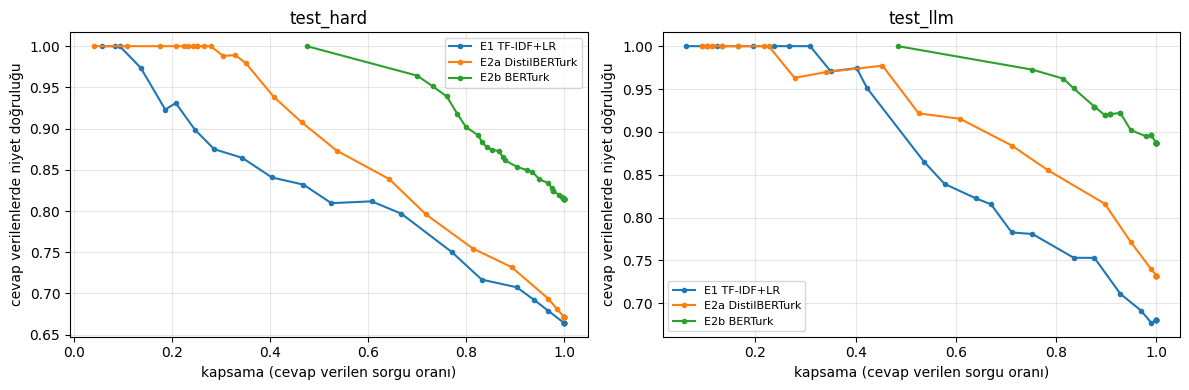

,Küme,Model,eşik,cevap verilen %,cevaplananlarda doğruluk
0,test_hard,E1 TF-IDF+LR,0.5,37.1,0.846
1,test_hard,E1 TF-IDF+LR,0.7,8.9,1.000
2,test_hard,E1 TF-IDF+LR,0.9,0.0,NaN
3,test_hard,E2a DistilBERTurk,0.5,42.1,0.932
4,test_hard,E2a DistilBERTurk,0.7,25.0,1.000
5,test_hard,E2a DistilBERTurk,0.9,10.7,1.000
6,test_hard,E2b BERTurk,0.5,95.0,0.838
7,test_hard,E2b BERTurk,0.7,86.1,0.871
8,test_hard,E2b BERTurk,0.9,76.1,0.939
9,test_llm,E1 TF-IDF+LR,0.5,54.6,0.849


In [ ]:
CONF_MODELS = [m for m in MODELS if m != "E0 Kural"]     # E0'ın güveni sabit
ths = np.linspace(0, 0.99, 34)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s in zip(axes, ["test_hard", "test_llm"]):
    for mn in CONF_MODELS:
        o = OUT[(mn, s)]; cov, acc = [], []
        for t in ths:
            keep = o.confidence >= t
            if keep.sum() >= 5:
                cov.append(keep.mean()); acc.append(o.intent_ok[keep].mean())
        ax.plot(cov, acc, marker=".", label=mn)
    ax.set_xlabel("kapsama (cevap verilen sorgu oranı)"); ax.set_ylabel("cevap verilenlerde niyet doğruluğu")
    ax.set_title(s); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("docs/week3/figures/cmp_risk_coverage.png", dpi=130); plt.show()

rows = []
for s in ["test_hard", "test_llm"]:
    for mn in CONF_MODELS:
        o = OUT[(mn, s)]
        for t in [0.5, 0.7, 0.9]:
            keep = o.confidence >= t
            rows.append({"Küme": s, "Model": mn, "eşik": t, "cevap verilen %": round(100 * keep.mean(), 1),
                         "cevaplananlarda doğruluk": round(o.intent_ok[keep].mean(), 3) if keep.any() else None})
display(pd.DataFrame(rows))

**Nasıl okunur?** Eğri sağ üste yakınsa model hem çok soruya cevap veriyor hem doğru cevap veriyor. Eşiği yükseltince doğruluk artıyorsa güven değeri anlamlıdır; bu, 'emin değilim' tasarımının kanıtıdır.

## 11. Gürültü dayanıklılığı

`test_llm` cümlelerine giderek daha fazla yazım hatası ekleyip (kelimelerin %0, 10, 20, 30, 50'si) başarının nasıl düştüğüne bakıyoruz. Kioskta kullanıcılar dokunmatik klavyede hızlı yazar; bu test gerçek kullanıma yakındır.

In [ ]:
from kiosk_nlu.generate_dataset import add_typo
def corrupt(text, p, rng):
    return " ".join(add_typo(t, rng) if rng.random() < p else t for t in text.split())
levels = [0.0, 0.1, 0.2, 0.3, 0.5]
base = D["test_llm"]
curve = {mn: [] for mn in MODELS}
for p in levels:
    rng = random.Random(123)
    d = base.copy(); d["text"] = [corrupt(t, p, rng) for t in base.text]
    for mn, m in MODELS.items():
        _, met = evaluate_split(m, d)
        curve[mn].append(met["intent_macro_f1"])
fig, ax = plt.subplots(figsize=(7, 4))
for mn, v in curve.items(): ax.plot([100 * p for p in levels], v, marker="o", label=mn)
ax.set_xlabel("yazım hatası eklenen kelime oranı (%)"); ax.set_ylabel("niyet makro-F1 (test_llm)")
ax.set_title("Gürültüye dayanıklılık"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("docs/week3/figures/cmp_noise.png", dpi=130); plt.show()
display(pd.DataFrame(curve, index=[f"%{int(100 * p)}" for p in levels]).round(3))

## 12. Boyut, hız ve başarı

,Parametre (M),Eğitim (sn),p95 gecikme (ms),Makro-F1 test_hard,Makro-F1 test_llm
E0 Kural,0.000,0.000,37.807,0.688,0.866
E1 TF-IDF+LR,0.030,5.543,11.287,0.673,0.717
E2a DistilBERTurk,136.233,105.766,15.399,0.670,0.770
E2b BERTurk,221.290,207.344,21.148,0.816,0.882


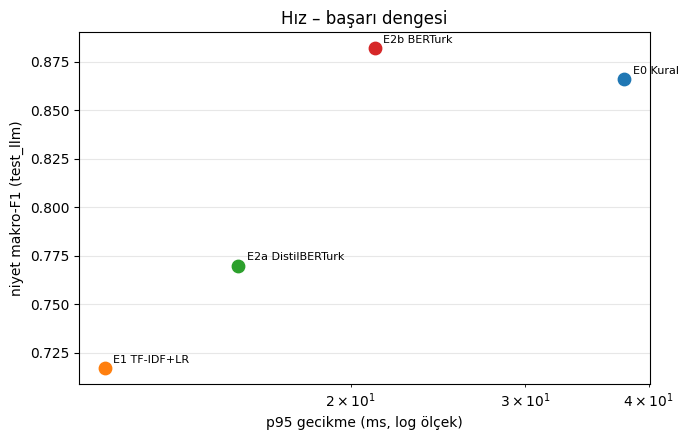

In [ ]:
trade = pd.DataFrame({
    "Parametre (M)": {mn: PARAMS[mn] / 1e6 for mn in MODELS},
    "Eğitim (sn)": TRAIN_SEC,
    "p95 gecikme (ms)": {mn: MET[(mn, "test_llm")]["latency_p95_ms"] for mn in MODELS},
    "Makro-F1 test_hard": {mn: MET[(mn, "test_hard")]["intent_macro_f1"] for mn in MODELS},
    "Makro-F1 test_llm": {mn: MET[(mn, "test_llm")]["intent_macro_f1"] for mn in MODELS},
}).round(3)
display(trade)
fig, ax = plt.subplots(figsize=(7, 4.5))
for mn in MODELS:
    ax.scatter(trade.loc[mn, "p95 gecikme (ms)"], trade.loc[mn, "Makro-F1 test_llm"], s=80)
    ax.annotate(mn, (trade.loc[mn, "p95 gecikme (ms)"], trade.loc[mn, "Makro-F1 test_llm"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("p95 gecikme (ms, log ölçek)"); ax.set_ylabel("niyet makro-F1 (test_llm)")
ax.set_title("Hız – başarı dengesi"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("docs/week3/figures/cmp_tradeoff.png", dpi=130); plt.show()

## 13. Otomatik özet (sunum için)

In [ ]:
lines = []
for s in ["test", "test_hard", "test_llm"]:
    best = max(MODELS, key=lambda mn: MET[(mn, s)]["intent_macro_f1"])
    lo, hi = CI[(best, s)][0]
    lines.append(f"- **{s}**: en iyi niyet makro-F1 = {best} ({MET[(best, s)]['intent_macro_f1']:.3f}, %95 GA [{lo:.2f}, {hi:.2f}]); "
                 f"en iyi varlık doğruluğu = {max(MODELS, key=lambda mn: MET[(mn, s)]['entity_acc'])} ({max(MET[(mn, s)]['entity_acc'] for mn in MODELS):.3f}).")
gap = {mn: MET[(mn, 'test')]['intent_macro_f1'] - MET[(mn, 'test_llm')]['intent_macro_f1'] for mn in MODELS}
lines.append("- **Genelleme açığı** (test − test_llm makro-F1): " + ", ".join(f"{mn}: {g:+.2f}" for mn, g in gap.items()))
q1 = [mn for mn in MODELS if MET[(mn, 'test_hard')]['intent_macro_f1'] >= TARGETS['intent_macro_f1_hard']]
lines.append("- **Q1 hedefini (test_hard ≥ 0,85) karşılayan modeller:** " + (", ".join(q1) if q1 else "henüz yok"))
SUMMARY_TEXT = "\n".join(lines); print(SUMMARY_TEXT)

- **test**: en iyi niyet makro-F1 = E1 TF-IDF+LR (1.000, %95 GA [1.00, 1.00]); en iyi varlık doğruluğu = E2b BERTurk (0.995).
- **test_hard**: en iyi niyet makro-F1 = E2b BERTurk (0.816, %95 GA [0.77, 0.85]); en iyi varlık doğruluğu = E2b BERTurk (0.809).
- **test_llm**: en iyi niyet makro-F1 = E2b BERTurk (0.882, %95 GA [0.80, 0.94]); en iyi varlık doğruluğu = E2b BERTurk (0.934).
- **Genelleme açığı** (test − test_llm makro-F1): E0 Kural: +0.01, E1 TF-IDF+LR: +0.28, E2a DistilBERTurk: +0.17, E2b BERTurk: +0.11
- **Q1 hedefini (test_hard ≥ 0,85) karşılayan modeller:** henüz yok


## 14. Sonuçları kaydet

In [ ]:
os.makedirs("results", exist_ok=True)
SUMMARY.round(4).to_csv("results/week3_summary.csv", index=False)
TARGET_TABLE.to_csv("results/week3_targets.csv", index=False)
trade.to_csv("results/week3_tradeoff.csv")
E.to_csv("results/week3_errors_test_llm.csv", index=False)
json.dump({f"{mn}|{s}": {k: float(v) for k, v in m.items()} for (mn, s), m in MET.items()},
          open("results/week3_metrics.json", "w"), indent=2, ensure_ascii=False)

with open("docs/week3/comparison.md", "w", encoding="utf-8") as f:
    f.write("# Hafta 3: Model kıyaslaması (E0 / E1 / E2a / E2b)\n\n")
    f.write("Colab'da çalıştırıldı: `notebooks/02_colab_week3.ipynb`. `test_llm` bir dil modeli tarafından yazılmıştır (gerçek kullanıcı verisi değildir).\n\n")
    f.write("## Özet\n\n" + SUMMARY_TEXT + "\n\n## Sonuç tablosu\n\n" + SUMMARY.round(3).to_markdown(index=False))
    f.write("\n\n## Hedefler (öneri formu)\n\n" + TARGET_TABLE.to_markdown(index=False))
    f.write("\n\n## Boyut, hız, başarı\n\n" + trade.to_markdown())
    f.write("\n\n## Grafikler\n\n" + "\n".join(f"![{n}](figures/{n}.png)" for n in
            ["cmp_macro_f1", "cmp_confusion_test_hard", "cmp_confusion_test_llm", "cmp_risk_coverage", "cmp_noise", "cmp_tradeoff"]) + "\n")
!zip -qr week3_sonuclar.zip results docs/week3 data/processed
print("hazır: week3_sonuclar.zip (sol paneldeki Dosyalar'dan indir)")

## 15. Sonuçları GitHub'a göndermek

1. Sol paneldeki **Dosyalar** simgesinden `week3_sonuclar.zip` dosyasını indir.
2. Zip'i bana (sohbete) yükle; repoya "Hafta 3: Colab sonuçları" olarak commit'leyeyim. Ya da yerel repo klasörüne çıkarıp `git add . && git commit && git push` yap.

## Sunumda kullanılacak ana fikirler

1. **Dağılım içi test yanıltıcı:** `test` kolay; asıl bilgi `test_hard` ve `test_llm`'de.
2. **Basit kural bile güçlü:** E0 ile E1/E2 arasındaki fark, makine öğrenmesinin neyi kattığını gösterir.
3. **Güven aralıkları:** Farkların anlamlı olup olmadığını söyler.
4. **Güven eşiği:** "Emin değilim" tasarımı yanlış rotayı azaltır.
5. **Sınırlar:** Veri sentetik/LLM yazımı; gerçek kullanıcı sorguları Hafta 5'e kadar toplanıp test setine eklenecek, E3 (küçük LLM + LoRA) eklenecek.